# Day 6 – Cleaned Dataset Verification & Order-Level Structure

## Objective
Verify the Day 5 cleaned dataset and understand its underlying order-item structure before beginning Week 2 KPI and business analysis.

### Scope
- Verify dataset dimensions, schema, data types, and data integrity.
- Check missing values, duplicate records, and Row ID uniqueness.
- Distinguish order-item rows from unique orders.
- Analyze the number of product lines per order.
- Build a separate order-level dataset through aggregation.
- Validate the order-level structure and document findings.

**Source:** `data/processed/cleaned_superstore.csv`

The Day 5 cleaned dataset is used as the input. The raw dataset and previous work will not be modified.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/cleaned_superstore.csv").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root could not be located.")

DATA_PATH = PROJECT_ROOT / "data/processed/cleaned_superstore.csv"

df = pd.read_csv(
    DATA_PATH,
    dtype={"Postal Code": "string"},
    parse_dates=["Order Date", "Ship Date"]
)

print("Dataset loaded successfully.")
print("Source:", DATA_PATH)
print("Shape:", df.shape)


Dataset loaded successfully.
Source: /Users/hemanth/Sales-Business-Performance-Analytics-Dashboard/data/processed/cleaned_superstore.csv
Shape: (10194, 21)


## 1. Dataset Overview

Review the number of records, fields, and the overall structure of the cleaned dataset.


In [2]:
print("ROWS:", len(df))
print("COLUMNS:", len(df.columns))
print("COLUMN NAMES:")
print(df.columns.tolist())

display(df.head())
display(df.info())


ROWS: 10194
COLUMNS: 21
COLUMN NAMES:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  string        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

None

## 2. Data Types Verification

Verify that date fields, identifiers, postal codes, and numeric measures have appropriate data types.


In [3]:
display(df.dtypes.to_frame("Data Type"))

expected_date_columns = ["Order Date", "Ship Date"]
expected_numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

print("\\nDate columns:")
for column in expected_date_columns:
    print(column, "->", df[column].dtype)

print("\\nNumeric columns:")
for column in expected_numeric_columns:
    print(column, "->", df[column].dtype)

print("\\nPostal Code dtype:", df["Postal Code"].dtype)


,Data Type
Row ID,int64
Order ID,str
Order Date,datetime64[us]
Ship Date,datetime64[us]
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country/Region,str
City,str


\nDate columns:
Order Date -> datetime64[us]
Ship Date -> datetime64[us]
\nNumeric columns:
Sales -> float64
Quantity -> int64
Discount -> float64
Profit -> float64
\nPostal Code dtype: string


## 3. Data Integrity Checks

Check missing values, duplicates, Row ID uniqueness, date validity, and shipping-date consistency.


In [4]:
missing_summary = df.isna().sum().sort_values(ascending=False)
duplicate_rows = df.duplicated().sum()
duplicate_row_ids = df["Row ID"].duplicated().sum()
invalid_order_dates = df["Order Date"].isna().sum()
invalid_ship_dates = df["Ship Date"].isna().sum()
ship_before_order = (df["Ship Date"] < df["Order Date"]).sum()

integrity_summary = pd.DataFrame({
    "Check": [
        "Total rows",
        "Total columns",
        "Missing values",
        "Duplicate rows",
        "Duplicate Row IDs",
        "Invalid Order Dates",
        "Invalid Ship Dates",
        "Ship Date before Order Date"
    ],
    "Result": [
        len(df),
        len(df.columns),
        int(df.isna().sum().sum()),
        int(duplicate_rows),
        int(duplicate_row_ids),
        int(invalid_order_dates),
        int(invalid_ship_dates),
        int(ship_before_order)
    ]
})

display(integrity_summary)
display(missing_summary.to_frame("Missing Values"))


,Check,Result
0,Total rows,10194
1,Total columns,21
2,Missing values,0
3,Duplicate rows,0
4,Duplicate Row IDs,0
5,Invalid Order Dates,0
6,Invalid Ship Dates,0
7,Ship Date before Order Date,0


,Missing Values
Row ID,0
Postal Code,0
Discount,0
Quantity,0
Sales,0
Product Name,0
Sub-Category,0
Category,0
Product ID,0
Region,0


## 4. Order-Level vs. Order-Item-Level Structure

Each row in the dataset represents an order item (a product line within an order), not necessarily an entire order.

Compare:
- Total dataset rows
- Unique order IDs
- Number of orders with one item
- Number of orders with multiple items
- Maximum item lines in a single order


In [5]:
total_order_item_rows = len(df)
unique_orders = df["Order ID"].nunique()

order_item_counts = (
    df.groupby("Order ID")
      .size()
      .rename("Order Item Count")
      .sort_values(ascending=False)
)

single_item_orders = (order_item_counts == 1).sum()
multi_item_orders = (order_item_counts > 1).sum()

order_structure_summary = pd.DataFrame({
    "Metric": [
        "Total order-item rows",
        "Unique orders",
        "Orders with one item",
        "Orders with multiple items",
        "Maximum items in one order",
        "Average items per order"
    ],
    "Value": [
        total_order_item_rows,
        unique_orders,
        single_item_orders,
        multi_item_orders,
        order_item_counts.max(),
        order_item_counts.mean()
    ]
})

display(order_structure_summary)
display(order_item_counts.describe().to_frame("Order Item Count Statistics"))


,Metric,Value
0,Total order-item rows,10194.000000
1,Unique orders,5111.000000
2,Orders with one item,2593.000000
3,Orders with multiple items,2518.000000
4,Maximum items in one order,14.000000
5,Average items per order,1.994522


,Order Item Count Statistics
count,5111.000000
mean,1.994522
std,1.409213
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,14.000000


## 5. Distribution of Order Item Counts

Examine how many product lines are included in each order.


,Items per Order,Number of Orders
0,1,2593
1,2,1242
2,3,612
3,4,344
4,5,164
5,6,72
6,7,51
7,8,16
8,9,10
9,10,3


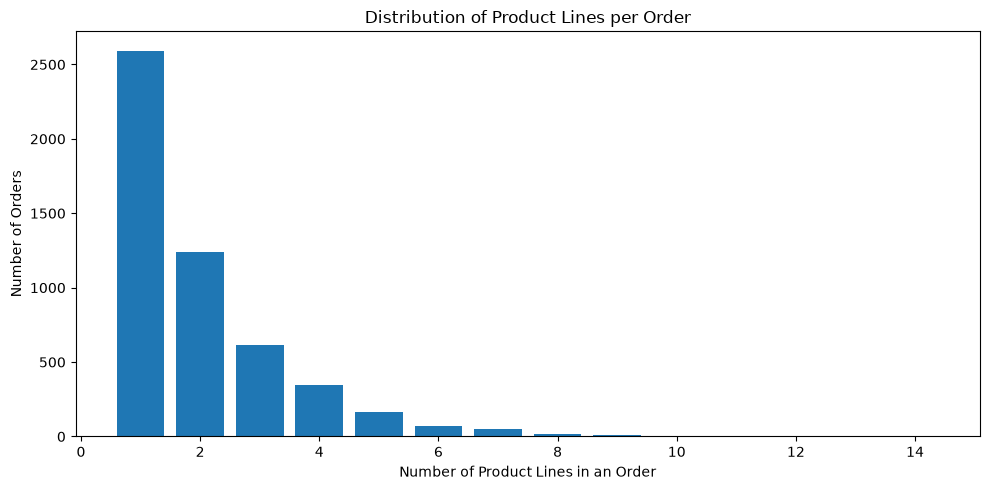

In [6]:
item_count_distribution = (
    order_item_counts.value_counts()
      .sort_index()
      .rename_axis("Items per Order")
      .reset_index(name="Number of Orders")
)

display(item_count_distribution)

plt.figure(figsize=(10, 5))
plt.bar(
    item_count_distribution["Items per Order"],
    item_count_distribution["Number of Orders"]
)
plt.title("Distribution of Product Lines per Order")
plt.xlabel("Number of Product Lines in an Order")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


## 6. Order-Level Aggregation

Create a separate order-level DataFrame by grouping order-item records.

Aggregation logic:
- Sales: sum across order items
- Profit: sum across order items
- Quantity: sum across order items
- Discount: average across order items
- Order Date: first observed date
- Ship Date: maximum shipping date
- Customer, segment, region, ship mode, and order status: first observed value
- Product line count: number of rows per order
- Product count: distinct products per order
- Category count: distinct categories per order

The aggregated dataset is temporary for Day 6 analysis; the source cleaned dataset remains unchanged.


In [7]:
order_level = (
    df.groupby("Order ID", as_index=False)
      .agg(
          Order_Date=("Order Date", "first"),
          Ship_Date=("Ship Date", "max"),
          Customer_ID=("Customer ID", lambda s: s.iloc[0] if s.nunique(dropna=False)==1 else "MULTIPLE"),
          Customer_ID_Conflict=("Customer ID", lambda s: s.nunique(dropna=False)>1),
          Customer_Name=("Customer Name", "first"),
          Segment=("Segment", "first"),
          Country_Region=("Country/Region", "first"),
          City=("City", lambda s: s.iloc[0] if s.nunique(dropna=False)==1 else "MULTIPLE"),
          City_Conflict=("City", lambda s: s.nunique(dropna=False)>1),
          State_Province=("State/Province", "first"),
          Postal_Code=("Postal Code", lambda s: s.iloc[0] if s.nunique(dropna=False)==1 else "MULTIPLE"),
          Postal_Code_Conflict=("Postal Code", lambda s: s.nunique(dropna=False)>1),
          Region=("Region", "first"),
          Ship_Mode=("Ship Mode", "first"),
          Order_Item_Count=("Row ID", "count"),
          Product_Count=("Product ID", "nunique"),
          Category_Count=("Category", "nunique"),
          Total_Sales=("Sales", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Average_Discount=("Discount", "mean"),
          Total_Profit=("Profit", "sum")
      )
)

print("Order-level dataset shape:", order_level.shape)
display(order_level.head())


Order-level dataset shape: (5111, 22)


,Order ID,Order_Date,Ship_Date,Customer_ID,Customer_ID_Conflict,Customer_Name,Segment,Country_Region,City,City_Conflict,...,Postal_Code_Conflict,Region,Ship_Mode,Order_Item_Count,Product_Count,Category_Count,Total_Sales,Total_Quantity,Average_Discount,Total_Profit
0,CA-2023-100867,2023-10-19,2023-10-24,EH-14125,False,Eugene Hildebrand,Home Office,Canada,Vancouver,False,...,False,West,Standard Class,1,1,1,32.700,3,0.0,8.5000
1,CA-2023-107153,2023-09-28,2023-10-03,GZ-14545,False,George Zrebassa,Corporate,Canada,Montreal,False,...,False,East,Standard Class,1,1,1,10.688,2,0.2,3.7408
2,CA-2023-115238,2023-01-21,2023-01-24,JW-15220,False,Jane Waco,Corporate,Canada,Toronto,False,...,False,East,Standard Class,5,5,3,281.160,22,0.0,89.2000
3,CA-2023-115777,2023-08-19,2023-08-24,DO-13645,False,Doug O'Connell,Consumer,Canada,Montreal,False,...,False,East,Standard Class,1,1,1,387.990,1,0.0,182.3600
4,CA-2023-117964,2023-12-02,2023-12-06,MK-19560,False,Michael Knudson,Corporate,Canada,Moncton,False,...,False,East,Standard Class,2,2,2,56.424,12,0.4,-18.5354


## 7. Order-Level Structure Validation

Verify that the aggregated dataset contains one record per order and that order totals reconcile with the order-item dataset.


In [8]:
order_level_validation = {
    "Unique order IDs in source": df["Order ID"].nunique(),
    "Rows in order-level dataset": len(order_level),
    "Duplicate order IDs in order-level dataset": order_level["Order ID"].duplicated().sum(),
    "Orders with conflicting Customer IDs": int(order_level["Customer_ID_Conflict"].sum()),
    "Orders with conflicting Cities": int(order_level["City_Conflict"].sum()),
    "Orders with conflicting Postal Codes": int(order_level["Postal_Code_Conflict"].sum()),
    "Source total sales": df["Sales"].sum(),
    "Order-level total sales": order_level["Total_Sales"].sum(),
    "Source total profit": df["Profit"].sum(),
    "Order-level total profit": order_level["Total_Profit"].sum(),
    "Source total quantity": df["Quantity"].sum(),
    "Order-level total quantity": order_level["Total_Quantity"].sum()
}

display(pd.Series(order_level_validation, name="Validation Result").to_frame())

assert len(order_level) == df["Order ID"].nunique()
assert order_level["Order ID"].is_unique
assert np.isclose(df["Sales"].sum(), order_level["Total_Sales"].sum())
assert np.isclose(df["Profit"].sum(), order_level["Total_Profit"].sum())
assert np.isclose(df["Quantity"].sum(), order_level["Total_Quantity"].sum())

print("Order-level validation: PASSED")


,Validation Result
Unique order IDs in source,5.111000e+03
Rows in order-level dataset,5.111000e+03
Duplicate order IDs in order-level dataset,0.000000e+00
Orders with conflicting Customer IDs,2.000000e+00
Orders with conflicting Cities,2.000000e+00
Orders with conflicting Postal Codes,2.000000e+00
Source total sales,2.326534e+06
Order-level total sales,2.326534e+06
Source total profit,2.922968e+05
Order-level total profit,2.922968e+05


Order-level validation: PASSED


## 8. Summary and Conclusion

Summarize the cleaned dataset verification and order-level structure.

Key distinction:
- Order-item-level dataset: each row represents a product line within an order.
- Order-level dataset: one row per Order ID, with product-line measures aggregated.

The order-level aggregation is created for analysis and does not replace the original cleaned dataset.
